In [1]:
import pandas as pd
from scipy.stats import hypergeom

gwas = pd.read_csv(r"C:\tri_disease_project\data\raw\gwas_all.tsv", sep="\t", low_memory=False)

# unrelated negative-control trait: schizophrenia (no established cardiometabolic mechanistic overlap)
control_mask = gwas['DISEASE/TRAIT'].str.contains('schizophrenia', case=False, na=False) & \
               ~gwas['DISEASE/TRAIT'].str.contains('metabolic|antipsychotic|weight|BMI', case=False, na=False)

gwas_control = gwas.loc[control_mask].copy()
print("Schizophrenia GWAS rows:", len(gwas_control))
print(gwas_control['DISEASE/TRAIT'].value_counts().head(10))

Schizophrenia GWAS rows: 6255
DISEASE/TRAIT
Schizophrenia                                                                                                                                                                                                3610
Schizophrenia (MTAG)                                                                                                                                                                                          381
Autism spectrum disorder or schizophrenia                                                                                                                                                                     301
Cognitive ability, years of educational attainment or schizophrenia (pleiotropy)                                                                                                                              235
Anorexia nervosa, attention-deficit/hyperactivity disorder, autism spectrum disorder, bipolar disorder, major depres

In [2]:
exclude_control = r'pleiotropy| or |,|response to|x sex|x .* interaction|combined|MTAG'

core_control_mask = control_mask & ~(gwas['DISEASE/TRAIT'].str.contains(exclude_control, case=False, regex=True, na=False))
gwas_control_core = gwas.loc[core_control_mask].copy()

print("Core schizophrenia rows:", len(gwas_control_core))
print(gwas_control_core['DISEASE/TRAIT'].value_counts())

def extract_gwas_genes(df):
    d = df[['MAPPED_GENE', 'P-VALUE']].dropna(subset=['MAPPED_GENE']).copy()
    d['gene_list'] = d['MAPPED_GENE'].str.split(r',\s*|\s+-\s+|\s+x\s+|;\s*')
    d = d.explode('gene_list')
    d['gene_list'] = d['gene_list'].str.strip()
    d = d[d['gene_list'] != '']
    d = d.rename(columns={'gene_list': 'symbol_raw', 'P-VALUE': 'pvalue'})
    gene_level = d.groupby('symbol_raw', as_index=False)['pvalue'].min()
    return gene_level

control_genes_raw = extract_gwas_genes(gwas_control_core)
print("\nUnique raw genes:", len(control_genes_raw))

mapping = pd.read_csv(r"C:\tri_disease_project\data\interim\gene_symbol_mapping.csv")
lookup = mapping.dropna(subset=['hgnc_symbol']).set_index('symbol_raw')['hgnc_symbol'].to_dict()

control_genes_raw['hgnc_symbol'] = control_genes_raw['symbol_raw'].map(lookup)
control_genes_std = control_genes_raw.dropna(subset=['hgnc_symbol'])

control_genes_sig = control_genes_std[control_genes_std['pvalue'] < 5e-8]
control_gene_set = set(control_genes_sig['hgnc_symbol'])

print("Genome-wide significant schizophrenia genes:", len(control_gene_set))

# compare against our 690 shared genes
shared_genes = pd.read_csv(r"C:\tri_disease_project\data\processed\shared_genes_protein_coding.csv")['hgnc_symbol'].tolist()
shared_in_control = [g for g in shared_genes if g in control_gene_set]

N = 20000
K = len(shared_genes)
n = len(control_gene_set)
overlap = len(shared_in_control)

pval = hypergeom.sf(overlap - 1, N, K, n)
print(f"\n=== Negative control: shared genes vs. schizophrenia GWAS ===")
print(f"Overlap: {overlap} / {K} shared genes found in {n} schizophrenia genes")
print(f"Hypergeometric p-value: {pval:.3e}")
print(f"Percent overlap: {100*overlap/K:.1f}%")

Core schizophrenia rows: 4125
DISEASE/TRAIT
Schizophrenia                                                                                    3610
Bipolar disorder and schizophrenia                                                                122
Schizophrenia vs ADHD (ordinary least squares (OLS))                                               43
Schizophrenia vs anorexia nervosa (ordinary least squares (OLS))                                   41
Schizophrenia vs autism spectrum disorder (ordinary least squares (OLS))                           40
Exploratory eye movement dysfunction in schizophrenia (responsive search score)                    21
Suicide attempts in schizophrenia                                                                  20
Exploratory eye movement dysfunction in schizophrenia (number of eye fixations)                    19
Exploratory eye movement dysfunction in schizophrenia (cognitive search score)                     15
Early-onset schizophrenia             

In [3]:
exclude_control_v2 = r'pleiotropy| or | and |,|response to|x sex|x .* interaction|combined|MTAG|diabetes|obesity|metabolic|weight|adverse drug|agranulocytosis|clozapine|aripiprazole|BMI'

core_control_mask_v2 = control_mask & ~(gwas['DISEASE/TRAIT'].str.contains(exclude_control_v2, case=False, regex=True, na=False))
gwas_control_core_v2 = gwas.loc[core_control_mask_v2].copy()

print("Core schizophrenia rows (v2):", len(gwas_control_core_v2))
print(gwas_control_core_v2['DISEASE/TRAIT'].value_counts().head(15))

control_genes_raw_v2 = extract_gwas_genes(gwas_control_core_v2)
control_genes_raw_v2['hgnc_symbol'] = control_genes_raw_v2['symbol_raw'].map(lookup)
control_genes_std_v2 = control_genes_raw_v2.dropna(subset=['hgnc_symbol'])
control_genes_sig_v2 = control_genes_std_v2[control_genes_std_v2['pvalue'] < 5e-8]
control_gene_set_v2 = set(control_genes_sig_v2['hgnc_symbol'])

print("\nGenome-wide significant schizophrenia genes (v2):", len(control_gene_set_v2))

shared_in_control_v2 = [g for g in shared_genes if g in control_gene_set_v2]
n2 = len(control_gene_set_v2)
overlap2 = len(shared_in_control_v2)
pval2 = hypergeom.sf(overlap2 - 1, N, K, n2)

print(f"\n=== Negative control (v2, comorbidity-cleaned) ===")
print(f"Overlap: {overlap2} / {K} shared genes found in {n2} schizophrenia genes")
print(f"Hypergeometric p-value: {pval2:.3e}")
print(f"Percent overlap: {100*overlap2/K:.1f}%")

print(f"\n=== Comparison ===")
print(f"Metabolic syndrome: 305/690 = 44.2%, p=7.6e-135")
print(f"Schizophrenia (control): {overlap2}/690 = {100*overlap2/K:.1f}%, p={pval2:.3e}")

Core schizophrenia rows (v2): 3917
DISEASE/TRAIT
Schizophrenia                                                                        3610
Schizophrenia vs ADHD (ordinary least squares (OLS))                                   43
Schizophrenia vs anorexia nervosa (ordinary least squares (OLS))                       41
Schizophrenia vs autism spectrum disorder (ordinary least squares (OLS))               40
Exploratory eye movement dysfunction in schizophrenia (responsive search score)        21
Suicide attempts in schizophrenia                                                      20
Exploratory eye movement dysfunction in schizophrenia (number of eye fixations)        19
Exploratory eye movement dysfunction in schizophrenia (cognitive search score)         15
Early-onset schizophrenia                                                              15
Schizophrenia vs bipolar disorder (ordinary least squares (OLS))                       12
Exploratory eye movement dysfunction in schizophren

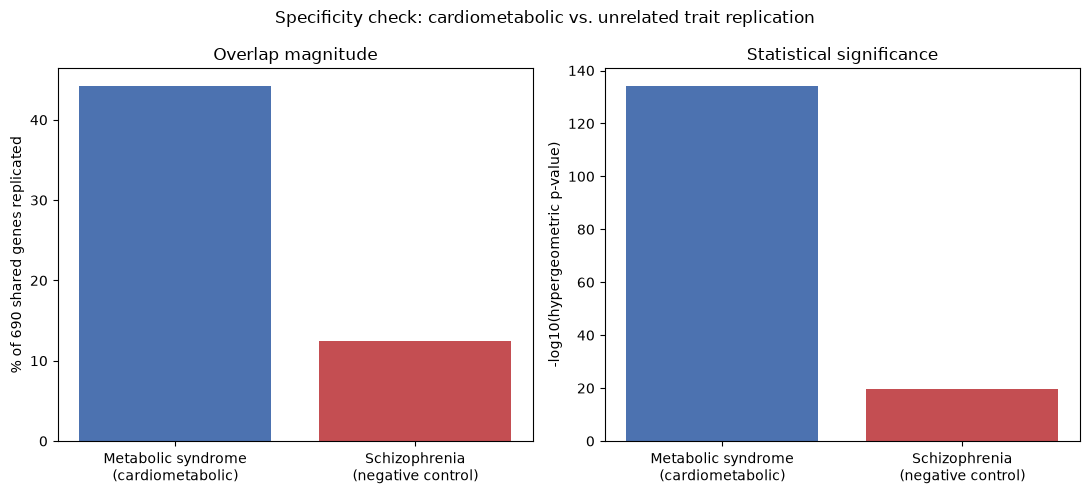

  Comparison trait                     Category  Genes replicated  Total shared genes  Percent  p_value
Metabolic syndrome   Cardiometabolic (positive)               305                 690     44.2 7.6e-135
     Schizophrenia Unrelated (negative control)                86                 690     12.5  1.8e-20


In [4]:
import matplotlib.pyplot as plt
import numpy as np

comparison_data = {
    'Metabolic syndrome\n(cardiometabolic)': {'overlap_pct': 44.2, 'neg_log_p': 134.12},
    'Schizophrenia\n(negative control)': {'overlap_pct': 12.5, 'neg_log_p': 19.74}
}

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

labels = list(comparison_data.keys())
pcts = [comparison_data[l]['overlap_pct'] for l in labels]
neglogs = [comparison_data[l]['neg_log_p'] for l in labels]
colors = ['#4C72B0', '#C44E52']

axes[0].bar(labels, pcts, color=colors)
axes[0].set_ylabel('% of 690 shared genes replicated')
axes[0].set_title('Overlap magnitude')

axes[1].bar(labels, neglogs, color=colors)
axes[1].set_ylabel('-log10(hypergeometric p-value)')
axes[1].set_title('Statistical significance')

plt.suptitle('Specificity check: cardiometabolic vs. unrelated trait replication')
plt.tight_layout()
plt.savefig(r"C:\tri_disease_project\results\figures\fig_extra_specificity_control.png", dpi=300, bbox_inches='tight')
plt.show()

# summary table for manuscript
summary_table = pd.DataFrame([
    {'Comparison trait': 'Metabolic syndrome', 'Category': 'Cardiometabolic (positive)', 'Genes replicated': 305, 'Total shared genes': 690, 'Percent': 44.2, 'p_value': '7.6e-135'},
    {'Comparison trait': 'Schizophrenia', 'Category': 'Unrelated (negative control)', 'Genes replicated': 86, 'Total shared genes': 690, 'Percent': 12.5, 'p_value': '1.8e-20'}
])
print(summary_table.to_string(index=False))
summary_table.to_csv(r"C:\tri_disease_project\results\tables\specificity_control_summary.csv", index=False)

In [5]:
comparator_genes = {
    'Dong et al. 2021': ['COL4A2', 'ACACB', 'GLUL', 'CD36'],
    'Norzagaray-Valenzuela et al. 2025': ['GNB1', 'JAK1', 'RPS3', 'MAPK1', 'BUB1B', 'RPS6', 'HNF4A', 'STAT2'],
    'Abdullah-Zawawi et al. 2025': ['STX3', 'VAMP2', 'DLAT', 'PDHX', 'OGDH', 'STAT5A']
}

records = []
for study, genes in comparator_genes.items():
    in_shared = [g for g in genes if g in shared_genes]
    in_hub = [g for g in genes if g in pd.read_csv(r"C:\tri_disease_project\results\tables\hub_genes_final.csv")['gene_symbol'].tolist()]
    records.append({
        'Comparator study': study,
        'Genes reported': len(genes),
        'Found in our 690 shared genes': len(in_shared),
        'Overlapping genes': ', '.join(in_shared) if in_shared else '(none)',
        'Found in our 17 hub genes': len(in_hub)
    })

comparator_df = pd.DataFrame(records)
print(comparator_df.to_string(index=False))
comparator_df.to_csv(r"C:\tri_disease_project\results\tables\comparator_gene_overlap.csv", index=False)

                 Comparator study  Genes reported  Found in our 690 shared genes Overlapping genes  Found in our 17 hub genes
                 Dong et al. 2021               4                              1              CD36                          0
Norzagaray-Valenzuela et al. 2025               8                              0            (none)                          0
      Abdullah-Zawawi et al. 2025               6                              0            (none)                          0


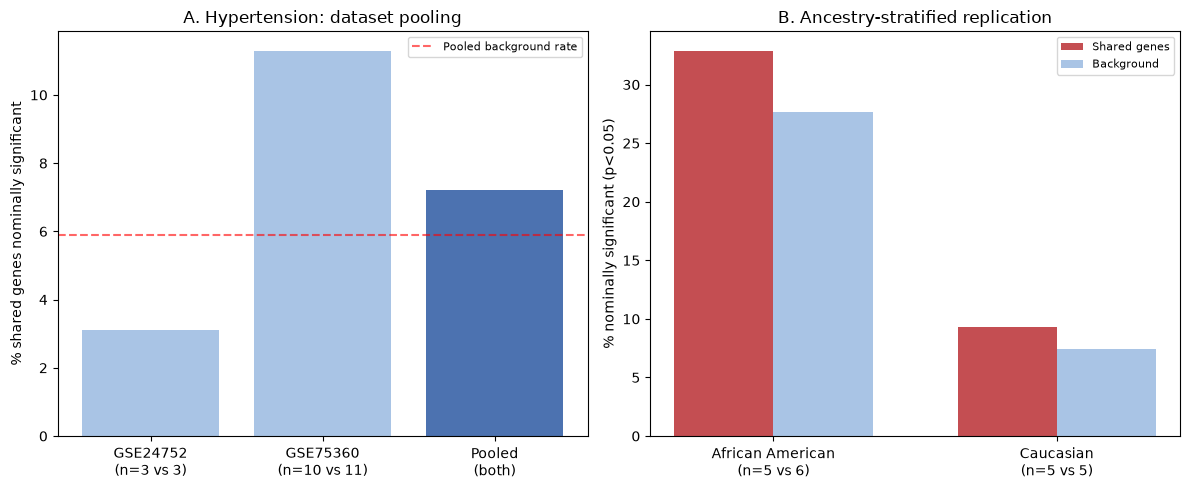

In [6]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Panel A: hypertension pooling
datasets = ['GSE24752\n(n=3 vs 3)', 'GSE75360\n(n=10 vs 11)', 'Pooled\n(both)']
pcts = [3.1, 11.3, 7.2]
pvals_neglog = [-np.log10(0.1102), -np.log10(0.1188), -np.log10(0.0320)]
colors1 = ['#A9C4E5', '#A9C4E5', '#4C72B0']

axes[0].bar(datasets, pcts, color=colors1)
axes[0].axhline(y=5.9, color='red', linestyle='--', alpha=0.6, label='Pooled background rate')
axes[0].set_ylabel('% shared genes nominally significant')
axes[0].set_title('A. Hypertension: dataset pooling')
axes[0].legend(fontsize=8)

# Panel B: ancestry stratification
subgroups = ['African American\n(n=5 vs 6)', 'Caucasian\n(n=5 vs 5)']
pcts_anc = [32.9, 9.3]
bg_anc = [27.7, 7.4]

x = np.arange(len(subgroups))
width = 0.35
axes[1].bar(x - width/2, pcts_anc, width, label='Shared genes', color='#C44E52')
axes[1].bar(x + width/2, bg_anc, width, label='Background', color='#A9C4E5')
axes[1].set_xticks(x)
axes[1].set_xticklabels(subgroups)
axes[1].set_ylabel('% nominally significant (p<0.05)')
axes[1].set_title('B. Ancestry-stratified replication')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(r"C:\tri_disease_project\results\figures\fig_extra_hypertension_ancestry.png", dpi=300, bbox_inches='tight')
plt.show()